# My guitar recordings

84 recordings, seven chords, three playing styles. This notebook reads the results of the existing model without fitting anything. Run `python -m src.personal_dataset` and `python -m src.evaluate_personal` from the project root to regenerate them.

## Load the saved results

Find the project folder and read three report files: the recording details, individual predictions, and overall scores. These cells inspect existing results; they do not run training.

In [5]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
REPORT = ROOT / "reports/marcus_recordings"
metadata = pd.read_csv(REPORT / "metadata.csv")
results = pd.read_csv(REPORT / "predictions.csv")
metrics = json.loads((REPORT / "metrics.json").read_text())

## Labels and recording order

Folder names are the correct chord labels. Numeric order only matters **within each folder**: the first four are downstrums, the next four repeated strumming, and the last four slow picking. Thumb/nail and the G variation were not recorded per file, so those fields remain unknown.

In [6]:
display(metadata[["original_filepath", "chord", "within_chord", "technique"]])
display(pd.crosstab(metadata.chord, metadata.technique))
display(metadata.duration_s.describe())

,original_filepath,chord,within_chord,technique
0,data/raw/data/marcus_recordings/A/Nytt opptak ...,A,1,downstrum
1,data/raw/data/marcus_recordings/A/Nytt opptak ...,A,2,downstrum
2,data/raw/data/marcus_recordings/A/Nytt opptak ...,A,3,downstrum
3,data/raw/data/marcus_recordings/A/Nytt opptak ...,A,4,downstrum
4,data/raw/data/marcus_recordings/A/Nytt opptak ...,A,5,repeated_strumming
...,...,...,...,...
79,data/raw/data/marcus_recordings/G/Nytt opptak ...,G,8,repeated_strumming
80,data/raw/data/marcus_recordings/G/Nytt opptak ...,G,9,slow_picking
81,data/raw/data/marcus_recordings/G/Nytt opptak ...,G,10,slow_picking
82,data/raw/data/marcus_recordings/G/Nytt opptak ...,G,11,slow_picking


technique,downstrum,repeated_strumming,slow_picking
chord,,,
A,4,4,4
Am,4,4,4
C,4,4,4
D,4,4,4
E,4,4,4
Em,4,4,4
G,4,4,4


count    84.000000
mean      5.658921
std       1.125785
min       3.648000
25%       4.576000
50%       5.600000
75%       6.400000
max       8.490667
Name: duration_s, dtype: float64

## How the existing model did

The model can still choose any of its 24 chords. No recordings were added to training. These results describe this personal collection, not all guitars or all chords.

Correct: 59/84 (70.2%)
Correct chord in top three: 94.0%
Rejected or failed: 0


,chord,recordings,correct,accuracy
0,A,12,2,0.166667
1,Am,12,12,1.000000
2,C,12,8,0.666667
3,D,12,8,0.666667
4,E,12,12,1.000000
5,Em,12,7,0.583333
6,G,12,10,0.833333


,technique,recordings,correct,accuracy
0,downstrum,28,23,0.821429
1,repeated_strumming,28,15,0.535714
2,slow_picking,28,21,0.750000


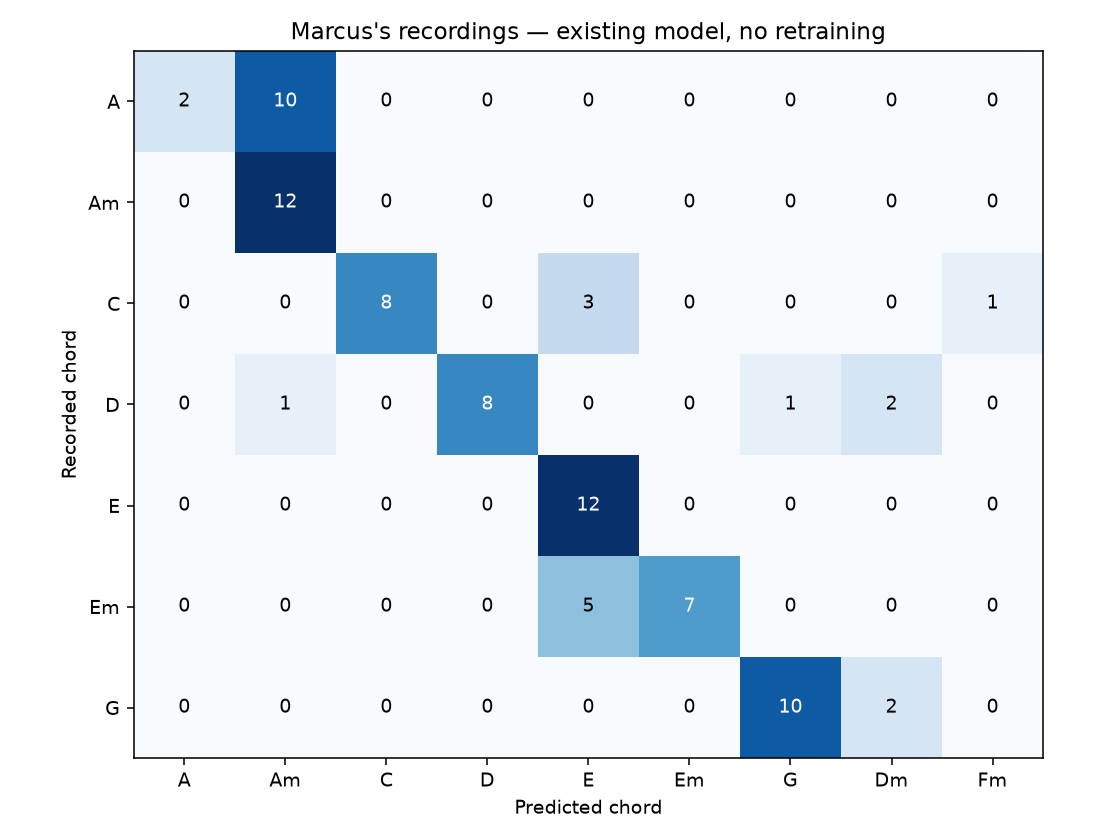

In [7]:
print(f"Correct: {metrics["correct"]}/{metrics["recordings"]} ({metrics["accuracy"]:.1%})")
print(f"Correct chord in top three: {metrics["top3_accuracy"]:.1%}")
print(f"Rejected or failed: {metrics["abstentions_or_errors"]}")
display(pd.read_csv(REPORT / "by_chord.csv"))
display(pd.read_csv(REPORT / "by_technique.csv"))
display(Image(filename=str(REPORT / "confusion_matrix.png")))

## What to inspect next

A was predicted as Am in 10 of 12 recordings, and Em as E in 5 of 12. Repeated strumming performed worst overall. This points to specific examples to listen to and inspect; it does not establish whether the cause is voicing, recording conditions, cropping or the feature/model choice.

The table below keeps file paths and crop boundaries so the actual mistakes can be checked. If these examples guide improvements, use a fresh recording session for a later independent test.

In [8]:
display(results.loc[results.chord != results.prediction,
    ["original_filepath", "chord", "technique", "prediction", "top_score", "start_s", "stop_s"]])

,original_filepath,chord,technique,prediction,top_score,start_s,stop_s
0,data/raw/data/marcus_recordings/A/Nytt opptak ...,A,downstrum,Am,0.300000,1.265488,4.010703
1,data/raw/data/marcus_recordings/A/Nytt opptak ...,A,downstrum,Am,0.313333,0.545669,3.545669
4,data/raw/data/marcus_recordings/A/Nytt opptak ...,A,repeated_strumming,Am,0.193333,0.673379,3.673379
5,data/raw/data/marcus_recordings/A/Nytt opptak ...,A,repeated_strumming,Am,0.206667,0.568889,3.568889
6,data/raw/data/marcus_recordings/A/Nytt opptak ...,A,repeated_strumming,Am,0.330000,0.278639,3.278639
7,data/raw/data/marcus_recordings/A/Nytt opptak ...,A,repeated_strumming,Am,0.220000,0.232200,3.232200
8,data/raw/data/marcus_recordings/A/Nytt opptak ...,A,slow_picking,Am,0.540000,1.102948,4.102948
9,data/raw/data/marcus_recordings/A/Nytt opptak ...,A,slow_picking,Am,0.340000,0.754649,3.754649
10,data/raw/data/marcus_recordings/A/Nytt opptak ...,A,slow_picking,Am,0.460000,0.162540,3.162540
11,data/raw/data/marcus_recordings/A/Nytt opptak ...,A,slow_picking,Am,0.343333,1.044898,4.044898
